# Notebook de núcleo algorítmico y programación orientada a objetos — Fase 3

**Proyecto:** Relación entre características de alojamientos frente a precios y niveles de
ocupación en Airbnb · Santiago de Chile · **Grupo 8** · MCDI500

---

### ¿Qué produce la Fase 3?

La Fase 2 dejó un *pipeline* que funciona: 18.904 anuncios crudos → 14.758 alojamientos
completos × 50 columnas, sin nulos y todo numérico. Pero vive en celdas sueltas: el orden
está implícito, nada se reutiliza sin copiar, no se puede probar por partes y la mediana y el
escalador se calculan sobre el conjunto completo (fuga de datos si después se particiona).

Esta fase toma **exactamente las mismas decisiones de la Fase 2** —ni una variable más, ni
un umbral distinto— y les da forma de **sistema**: cada paso es una clase, los pasos se
componen en un `Pipeline`, el código reutilizable vive en `src/` y el cuaderno lo importa.
El flujo es:

**Configurar → Cargar → Modelar en clases → Componer → Verificar (= F2) → Particionar sin fuga → Medir → Documentar → Persistir**

> **La prueba que gobierna todo el cuaderno.** Si el *pipeline* de clases produce
> **el mismo resultado** que el código de la Fase 2, la reorganización no rompió nada.
> Esa comparación se ejecuta con `pandas.testing.assert_frame_equal` en la sección 5.

| Sección | Contenido | Criterio de la rúbrica |
|---|---|---|
| 1 | Configuración única y entorno | Codificación funcional |
| 2 | Carga y verificación del esquema (90 → 13 columnas) | Preprocesamiento |
| 3 | De funciones a objetos: clase base, encapsulamiento, herencia, polimorfismo | POO |
| 4 | El pipeline de la Fase 2 como objetos (con bitácora automática) | Diseño estructurado |
| 5 | Verificación: el resultado es idéntico al de la Fase 2 | Validación técnica |
| 6 | Partición entrenamiento/prueba sin fuga de datos | Preprocesamiento |
| 7 | Pruebas: casos normales, límite y excepciones, con registro | Validación técnica |
| 8 | Eficiencia: cuatro implementaciones, `timeit` + `tracemalloc`, crecimiento | Eficiencia y optimización |
| 9 | Recursividad sobre los parámetros del pipeline | Diseño estructurado |
| 10 | Patrones de diseño usados (y uno descartado) | Documentación de arquitectura |
| 11 | Cohesión, acoplamiento y arquitectura generada desde el código | Diseño estructurado |
| 12 | Persistencia, contrato con la Fase 4 y verificación de entrega | Documentación |
| 13 | Reflexión técnica y bibliografía | Documentación |

## 1. Configuración única y entorno

**Qué hace este paso.** Localiza la raíz del repositorio, agrega `src/` a la ruta de
importación y carga la configuración del estudio desde `src/config.py`.

**Por qué así.** En el avance anterior la celda de configuración declaraba 19 columnas
distintas de las 12 que la Fase 2 justificó, incluía dos columnas 100 % vacías
(`bathrooms`, `instant_bookable`) y la variable objetivo se redefinía a mitad del cuaderno.
La causa era una sola: la configuración estaba **copiada a mano**. Ahora las decisiones
viven en **un** módulo que las Fases 2, 3 y 4 comparten. Si una decisión cambia, cambia en
un lugar.

In [2]:
import sys
import json
import platform
import time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt


def localizar_raiz(inicio=None):
    """Raíz del proyecto aunque Jupyter abra el kernel en F1/F2/F3/F4."""
    inicio = Path.cwd() if inicio is None else Path(inicio)
    return inicio.parent if inicio.name in {"F1", "F2", "F3", "F4"} else inicio


RAIZ = localizar_raiz()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))          # permite `from src import ...`

from src import config as cfg
from src import carga, transformadores as tr, pipeline as pl, observadores as ob
from src import fabrica, medicion, estructuras

np.random.seed(cfg.SEMILLA)

print("Raíz del proyecto :", RAIZ.resolve())
print("Python            :", sys.version.split()[0], "·", platform.system())
print("pandas / numpy    :", pd.__version__, "/", np.__version__)
import sklearn; print("scikit-learn      :", sklearn.__version__)
print("Semilla           :", cfg.SEMILLA)

Raíz del proyecto : C:\Users\Giuliano\Desktop\grupo_8_magister_mcdi500
Python            : 3.13.16 · Windows
pandas / numpy    : 3.1.1 / 2.5.4
scikit-learn      : 1.9.1
Semilla           : 42


La configuración se **lee**, no se escribe. Lo que sigue es lo que la Fase 2 decidió y
justificó con cifras (secciones 2 a 5 de ese cuaderno):

In [3]:
print("Filtro del estudio     :", f"{cfg.COLUMNA_FILTRO} == '{cfg.VALOR_FILTRO}'")
print("Objetivos (no se imputan ni escalan):", cfg.OBJETIVOS)
for grupo, variables in cfg.EXPLICATIVAS.items():
    print(f"Explicativas · {grupo:<12}:", variables)
print("\nTope maximum_nights    :", cfg.TOPE_MAXIMUM_NIGHTS)
print("Umbral precio imposible:", f"${cfg.UMBRAL_PRECIO:,.0f}")
print("Imputación (mediana)   :", cfg.COLUMNAS_IMPUTAR, "· bandera en", cfg.COLUMNA_CON_BANDERA)
print("Indicadores comodidades:", list(cfg.COMODIDADES))
print("One-hot                :", cfg.NOMINALES)
print("Escalado robusto       :", cfg.COLUMNAS_ESCALAR)
print(f"\nVariables del estudio: {len(cfg.VARIABLES_ESTUDIO)} · columnas requeridas del crudo: {len(cfg.COLUMNAS_REQUERIDAS)}")

Filtro del estudio     : room_type == 'Entire home/apt'
Objetivos (no se imputan ni escalan): ['price', 'estimated_occupancy_l365d']
Explicativas · comodidades : ['amenities']
Explicativas · capacidad   : ['accommodates', 'bedrooms', 'beds']
Explicativas · ubicacion   : ['neighbourhood_cleansed', 'latitude']
Explicativas · control     : ['host_is_superhost', 'minimum_nights', 'maximum_nights']

Tope maximum_nights    : 1125
Umbral precio imposible: $10,000,000
Imputación (mediana)   : ['accommodates', 'latitude', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights'] · bandera en bedrooms
Indicadores comodidades: ['tiene_aire_acondicionado', 'tiene_estacionamiento', 'tiene_piscina', 'tiene_lavadora', 'tiene_gimnasio', 'tiene_ascensor', 'tiene_espacio_trabajo', 'tiene_self_checkin']
One-hot                : {'host_is_superhost': 'superhost', 'neighbourhood_cleansed': 'comuna'}
Escalado robusto       : ['accommodates', 'latitude', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 

## 2. Carga y verificación del esquema

**Qué hace este paso.** Lee `data/raw/datasetairbnb.csv` con `src/carga.py` y verifica que
traiga las 13 columnas que el estudio necesita: las 12 variables de la Fase 2 más `room_type`
(solo para filtrar) e `id` (solo para verificar unicidad).

**Por qué 13 y no 90.** El criterio de selección se fijó en las fases anteriores y no se
rehace aquí: la Fase 1 documentó 14 columnas 100 % vacías y la Fase 2 descartó 3 constantes
y conservó solo las variables que responden la pregunta de investigación (comodidades,
capacidad, ubicación, control y los dos objetivos). Las 77 columnas restantes **no se
cargan al pipeline**: el avance anterior las arrastraba sin tratamiento y terminaba con 187
columnas y 40 de ellas con nulos.

In [4]:
ARCHIVO_CRUDO = RAIZ / cfg.ARCHIVO_CRUDO
datos, informe_carga = carga.cargar(ARCHIVO_CRUDO, cfg.COLUMNAS_REQUERIDAS)

assert datos[cfg.COLUMNA_ID].is_unique, "'id' tiene repetidos: revisar antes de continuar"
print("Archivo :", ARCHIVO_CRUDO.as_posix())
for clave, valor in informe_carga.items():
    print(f"  {clave:<22} {valor}")

Archivo : c:/Users/Giuliano/Desktop/grupo_8_magister_mcdi500/data/raw/datasetairbnb.csv
  filas                  18904
  columnas_archivo       90
  columnas_requeridas    13
  columnas_no_usadas     77


Perfil de entrada **solo de las columnas requeridas**: es la línea base contra la que se
verifica cada transformación. `price` llega como texto y `maximum_nights` con valores
imposibles, exactamente como documentó la Fase 2.

In [5]:
def perfilar(df, columnas):
    """Una fila por columna: tipo, únicos, nulos y rango. Funciona con cualquier conjunto."""
    filas = []
    for c in columnas:
        s = df[c]
        numerica = pd.api.types.is_numeric_dtype(s)
        filas.append({
            "columna": c, "tipo": str(s.dtype), "unicos": int(s.nunique(dropna=True)),
            "pct_nulos": round(float(s.isna().mean() * 100), 2),
            "min": s.min() if numerica else "", "max": s.max() if numerica else "",
            "ejemplo": str(s.dropna().iloc[0])[:28] if s.notna().any() else "",
        })
    return pd.DataFrame(filas)


perfil_entrada = perfilar(datos, cfg.COLUMNAS_REQUERIDAS)
print(perfil_entrada.to_string(index=False))

                  columna    tipo  unicos  pct_nulos        min                 max      ejemplo
                       id   int64   18904       0.00      49392 1780801299581407023        49392
                room_type     str       4       0.00                                Private room
                    price     str   10084       4.75                                  $59,303.00
estimated_occupancy_l365d   int64      88       0.00          0                 255            0
                amenities     str   17712       0.00                                          []
             accommodates   int64      16       0.00          1                  16            1
                 bedrooms float64      21       0.03        0.0                24.0          1.0
                     beds float64      25       1.07        1.0                57.0          1.0
   neighbourhood_cleansed     str      32       0.00                                 Providencia
                 latitude floa

## 3. De funciones a objetos

### 3.1 Por qué

El código de la Fase 2 tiene cuatro problemas que aparecen cuando el proyecto crece:

| Problema en F2 | Consecuencia | Cómo lo resuelve la POO |
|---|---|---|
| El orden de las celdas importa y no está declarado | Ejecutar fuera de orden da otro resultado (nos pasó: el escalador se aplicó dos veces) | El `Pipeline` guarda el orden como dato |
| No se reutiliza sin copiar | El mismo código se duplicaría en F3 y F4 | Las clases viven en `src/` y se importan |
| No se puede probar por partes | Si la salida está mal hay que revisar todo | Cada paso se prueba solo, con tres filas |
| Mediana y RIC se calculan sobre todo el conjunto | Fuga de datos al particionar | `ajustar` aprende solo del entrenamiento; `transformar` aplica |

### 3.2 La clase base: el contrato

`Transformador` (en `src/transformadores.py`) define lo que **todo paso comparte**:

- **`ajustar(df)`**: valida la entrada, delega el cálculo a `aprender()` y marca el estado.
- **`transformar(df)`**: exige haber ajustado, copia el `DataFrame` y delega a `aplicar()`.
- Estado **interno** con guion bajo (`_parametros`, `_ajustado`) y propiedades de solo lectura
  (`parametros`, `ajustado`, `nombre`): eso es **encapsulamiento**.
- `aprender()` y `aplicar()` lanzan `NotImplementedError`: la base no sabe *qué* se aprende,
  solo *cuándo*. Cada hija completa únicamente eso: eso es **herencia**.

La base no se usa sola:

In [6]:
try:
    tr.Transformador("price").ajustar(datos)
except NotImplementedError as error:
    print("NotImplementedError:", error)

NotImplementedError: Transformador debe implementar aprender().


### 3.3 Encapsulamiento: convertir un error silencioso en uno visible

Sin el control de `_ajustado`, transformar antes de ajustar produciría un resultado sin
sentido **y sin ningún mensaje**. Con él, el uso incorrecto falla de inmediato y con un
mensaje propio del proyecto (`ErrorDePipeline`), distinguible de un error de pandas.

In [7]:
imputador = tr.ImputadorMediana("beds")

try:
    imputador.transformar(datos)
except tr.ErrorDePipeline as error:
    print("ErrorDePipeline:", error)

imputador.ajustar(datos)
print("\nParámetros aprendidos:", imputador.parametros)

# Las propiedades son de solo lectura: el estado no se corrompe desde fuera
try:
    imputador.ajustado = False
except AttributeError as error:
    print("AttributeError:", error)

# parametros devuelve una COPIA: modificarla no toca el objeto (copia defensiva)
copia = imputador.parametros
copia["valor"] = -999
print("Tras modificar la copia, el objeto conserva:", imputador.parametros["valor"])

ErrorDePipeline: ImputadorMediana(beds): hay que ajustar antes de transformar.

Parámetros aprendidos: {'estrategia': 'mediana', 'valor': 2.0, 'nulos_en_ajuste': 203}
AttributeError: property 'ajustado' of 'ImputadorMediana' object has no setter
Tras modificar la copia, el objeto conserva: 2.0


### 3.4 Herencia: una jerarquía por paso del pipeline

Cada decisión de la Fase 2 es una clase hija que implementa solo `aprender` y `aplicar`.
La tabla se genera **leyendo las clases que existen** (`__subclasses__()`, recorrido de forma
recursiva para incluir nietas como `ImputadorMediana`), así no queda desactualizada.

In [8]:
def descendientes(clase):
    """Todas las subclases, directas e indirectas (recursivo)."""
    hijas = []
    for hija in clase.__subclasses__():
        hijas.append(hija)
        hijas.extend(descendientes(hija))
    return hijas


jerarquia = pd.DataFrame([{
    "clase": c.__name__,
    "hereda_de": c.__bases__[0].__name__,
    "responsabilidad": (c.__doc__ or "").strip().split("\n")[0],
} for c in descendientes(tr.Transformador)])
print(jerarquia.to_string(index=False))

               clase     hereda_de                                                                             responsabilidad
     FiltroCategoria Transformador         Conserva las filas cuya columna vale `valor` (F2 §3a: solo alojamientos completos).
    SelectorColumnas Transformador                    Conserva solo las variables del estudio, en el orden declarado (F2 §3a).
   ConvertidorMoneda Transformador     Convierte texto monetario ('$55,106.00') a número (F2 §2). Lo no convertible queda NaN.
    AcotadorSuperior Transformador Acota los valores sobre `tope` (F2 §3b: maximum_nights a 1125, el máximo de la plataforma).
     EliminadorNulos Transformador        Elimina filas con nulos en las columnas dadas (F2 §3c: los objetivos no se imputan).
        FiltroMaximo Transformador      Elimina filas con valor sobre `maximo` (F2 §3d: precios imposibles sobre $10.000.000).
    FiltroCoherencia Transformador          Elimina filas donde columna_a > columna_b (F2 §3d: más dormitorios 

In [9]:
# Comprobación de la herencia, no por fe: isinstance, MRO y dónde está definido cada método
paso = tr.ImputadorMediana("bedrooms", bandera=True)
print("¿Es ImputadorMediana?  ", isinstance(paso, tr.ImputadorMediana))
print("¿Es Imputador?         ", isinstance(paso, tr.Imputador))
print("¿Es Transformador?     ", isinstance(paso, tr.Transformador))
print("Cadena de herencia (MRO):", [c.__name__ for c in type(paso).__mro__])

print("\nDónde está definido cada método que el objeto sabe ejecutar:")
for metodo in ["ajustar", "transformar", "ajustar_transformar", "aprender", "aplicar", "__init__"]:
    for clase in type(paso).__mro__:
        if metodo in clase.__dict__:
            print(f"  {metodo:<22} -> {clase.__name__}")
            break

¿Es ImputadorMediana?   True
¿Es Imputador?          True
¿Es Transformador?      True
Cadena de herencia (MRO): ['ImputadorMediana', 'Imputador', 'Transformador', 'object']

Dónde está definido cada método que el objeto sabe ejecutar:
  ajustar                -> Transformador
  transformar            -> Transformador
  ajustar_transformar    -> Transformador
  aprender               -> Imputador
  aplicar                -> Imputador
  __init__               -> ImputadorMediana


### 3.5 Polimorfismo: la misma llamada para pasos distintos

Quien usa los pasos no pregunta de qué tipo son: todos responden a `ajustar_transformar`.
El bucle siguiente mezcla un filtro de filas, una conversión de texto, una imputación con
bandera, una codificación y un escalador, y los trata igual.

In [10]:
pasos_demo = [
    tr.FiltroCategoria(cfg.COLUMNA_FILTRO, cfg.VALOR_FILTRO),
    tr.SelectorColumnas(cfg.VARIABLES_ESTUDIO),
    tr.ConvertidorMoneda("price"),
    tr.ImputadorMediana("bedrooms", bandera=True),
    tr.CodificadorNominal("host_is_superhost", "superhost"),
    tr.EscaladorRobusto(["accommodates", "beds"]),
]

intermedio = datos.copy()
for paso in pasos_demo:                       # misma llamada polimórfica para todos
    intermedio = paso.ajustar_transformar(intermedio)
    print(f"{paso.nombre:<42} -> {intermedio.shape}")

FiltroCategoria(room_type)                 -> (15383, 90)
SelectorColumnas(11 columnas)              -> (15383, 11)
ConvertidorMoneda(price)                   -> (15383, 11)
ImputadorMediana(bedrooms)                 -> (15383, 12)
CodificadorNominal(host_is_superhost)      -> (15383, 13)
EscaladorRobusto(2 columnas)               -> (15383, 13)


> **Evidencia de los tres principios, para el informe.** *Herencia*: ninguna hija repite el
> control de estado. *Polimorfismo*: el bucle (y el `Pipeline`) llama `ajustar_transformar`
> sin preguntar el tipo. *Encapsulamiento*: `_parametros` y `_ajustado` son internos, con
> validación antes de actuar. Consecuencia práctica: **agregar un transformador nuevo no
> obliga a tocar el bucle ni el `Pipeline`**. Eso es bajo acoplamiento.

## 4. El pipeline de la Fase 2 como objetos

**Qué hace este paso.** `src/fabrica.py` construye los 17 pasos de la Fase 2 **en su orden
exacto** (delimitar → convertir precio → acotar → eliminar nulos de objetivos → imputar →
filtrar imposibles → comodidades → one-hot → escalar). Se usa un `PipelineObservable`
con dos observadores: `Bitacora` (acumula en una tabla) y `ReporteConsola` (imprime).

**Por qué un pipeline observable.** La bitácora de decisiones de la Fase 2 se escribió a
mano. Aquí se **genera en cada ejecución**, con filas antes/después, columnas y tiempo por
paso, de modo que no puede quedar desactualizada (patrón *Observer*, sección 10).

In [11]:
bitacora = ob.Bitacora()
pipeline_f2 = fabrica.construir_pipeline_f2(pl.PipelineObservable)
pipeline_f2.suscribir(bitacora).suscribir(ob.ReporteConsola())

print(pipeline_f2)
print("\nEjecución (ajuste y transformación sobre el conjunto completo, como en F2):")
procesado_f3 = pipeline_f2.ajustar_transformar(datos)

print(f"\nResultado: {procesado_f3.shape[0]} filas × {procesado_f3.shape[1]} columnas · "
      f"nulos = {int(procesado_f3.isna().sum().sum())} · "
      f"no numéricas = {procesado_f3.select_dtypes(exclude='number').shape[1]}")

Pipeline(17 pasos, sin ajustar)

Ejecución (ajuste y transformación sobre el conjunto completo, como en F2):
  [ajuste] FiltroCategoria(room_type)                      18904 ->  15383 filas,  90 col  [0.0309s]
  [ajuste] SelectorColumnas(11 columnas)                   15383 ->  15383 filas,  11 col  [0.0100s]
  [ajuste] ConvertidorMoneda(price)                        15383 ->  15383 filas,  11 col  [0.0386s]
  [ajuste] AcotadorSuperior(maximum_nights)                15383 ->  15383 filas,  11 col  [0.0029s]
  [ajuste] EliminadorNulos(2 columnas)                     15383 ->  14779 filas,  11 col  [0.0050s]
  [ajuste] ImputadorMediana(accommodates)                  14779 ->  14779 filas,  11 col  [0.0012s]
  [ajuste] ImputadorMediana(latitude)                      14779 ->  14779 filas,  11 col  [0.0012s]
  [ajuste] ImputadorMediana(bedrooms)                      14779 ->  14779 filas,  12 col  [0.0015s]
  [ajuste] ImputadorMediana(beds)                          14779 ->  14779 filas,  

La bitácora generada por la ejecución (solo la fase de transformación). Cada fila es una
decisión de la Fase 2 con su efecto medido; en el conjunto completo debe reproducir
18.904 → 15.383 (filtro) → 14.779 (sin precio) → 14.758 (imposibles) filas.

In [12]:
tabla_bitacora = bitacora.a_dataframe()
print(tabla_bitacora[tabla_bitacora["fase"] == "transformacion"]
      .drop(columns=["fase"]).to_string(index=False))

                                      paso  filas_antes  filas_despues  filas_eliminadas  columnas_despues  columnas_delta  segundos                                                                                 parametros
                FiltroCategoria(room_type)        18904          15383              3521                90               0   0.04035 {'valor': 'Entire home/apt', 'conservadas_en_ajuste': 15383, 'descartadas_en_ajuste': 3...
             SelectorColumnas(11 columnas)        15383          15383                 0                11             -79   0.01314                                                     {'conservadas': 11, 'descartadas': 79}
                  ConvertidorMoneda(price)        15383          15383                 0                11               0   0.02044                                               {'ya_numerica': False, 'no_convertibles': 0}
          AcotadorSuperior(maximum_nights)        15383          15383                 0                

## 5. Verificación: el resultado es idéntico al de la Fase 2

**Qué hace este paso.** Compara la salida del pipeline de clases con dos oráculos:

1. **`referencia_f2()`** (`F3/referencia_f2.py`): transcripción literal, celda por celda,
   del código de la Fase 2 en una función. Se ejecuta sobre los mismos datos crudos.
2. **`data/processed/airbnb_procesado.csv`**: el archivo que la Fase 2 entregó. Si existe
   en el repositorio, se compara también contra él (tolerancia numérica de lectura CSV).

`assert_frame_equal` exige igualdad de **valores, tipos, nombres y orden de columnas e
índice**. Si pasa, la reorganización en objetos no alteró nada.

In [13]:
sys.path.insert(0, str(RAIZ / "F3"))
from referencia_f2 import referencia_f2

esperado_f2 = referencia_f2(datos, cfg)
pd.testing.assert_frame_equal(esperado_f2, procesado_f3)
print(f"[OK] Pipeline de clases == transcripción de F2 "
      f"({procesado_f3.shape[0]} filas × {procesado_f3.shape[1]} columnas, "
      f"{procesado_f3.shape[1]} columnas y dtypes idénticos)")

ARCHIVO_F2 = RAIZ / cfg.ARCHIVO_PROCESADO_F2
if ARCHIVO_F2.exists():
    guardado_f2 = pd.read_csv(ARCHIVO_F2)
    pd.testing.assert_frame_equal(guardado_f2, procesado_f3, check_exact=False, rtol=1e-9)
    print(f"[OK] Pipeline de clases == {ARCHIVO_F2.name} entregado por la Fase 2")
else:
    print(f"[INFO] {ARCHIVO_F2.as_posix()} no está en esta copia del repositorio: "
          "ejecute el cuaderno F2 y vuelva a correr esta celda para la segunda comparación.")

[OK] Pipeline de clases == transcripción de F2 (14758 filas × 50 columnas, 50 columnas y dtypes idénticos)
[OK] Pipeline de clases == airbnb_procesado.csv entregado por la Fase 2


## 6. Partición entrenamiento/prueba sin fuga de datos

**Qué hace este paso.** Separa 80/20 con la semilla del proyecto, **ajusta el pipeline solo
con entrenamiento** y lo aplica a ambos conjuntos. Es la mejora que la Fase 2 dejó declarada
como decisión abierta ("la partición obligará a rehacer la imputación y el escalamiento
dentro de un pipeline").

**Qué significa para cada paso.**
- Los pasos que *aprenden* (medianas, vocabulario one-hot, centro y escala del robusto) usan
  solo entrenamiento. En prueba, la mediana de la columna escalada **no da exactamente 0**:
  es la confirmación de que no vio esos datos.
- Los pasos que *filtran filas* (alojamientos completos, sin precio, precios imposibles,
  capacidad incoherente) son reglas fijas y se aplican igual a prueba: un anuncio sin precio
  no sirve para evaluar, se trate del conjunto que se trate.
- Una comuna que solo aparezca en prueba **no genera columna**: el vocabulario se aprendió en
  el ajuste, así que entrenamiento y prueba quedan con el mismo esquema.

In [14]:
entrenamiento = datos.sample(frac=1 - cfg.PROPORCION_PRUEBA, random_state=cfg.SEMILLA)
prueba = datos.drop(index=entrenamiento.index)

pipeline_final = fabrica.construir_pipeline_f2()
pipeline_final.ajustar(entrenamiento)                       # aprende SOLO de entrenamiento
entrenamiento_final = pipeline_final.transformar(entrenamiento)
prueba_final = pipeline_final.transformar(prueba)

print(f"Entrenamiento: {entrenamiento.shape} -> {entrenamiento_final.shape}")
print(f"Prueba       : {prueba.shape} -> {prueba_final.shape}")
assert list(entrenamiento_final.columns) == list(prueba_final.columns), "Esquemas distintos"
print("Mismo esquema en ambos conjuntos:", entrenamiento_final.shape[1], "columnas\n")

escalador = pipeline_final.pasos[-1]
centro = escalador.parametros["centro"]
print("Mediana tras escalar (centro aprendido en entrenamiento):")
for col in cfg.COLUMNAS_ESCALAR[:4]:
    print(f"  {col:<16} entrenamiento = {entrenamiento_final[col].median():>7.3f}   "
          f"prueba = {prueba_final[col].median():>7.3f}   (centro aprendido: {centro[col]:.3f})")

Entrenamiento: (15123, 90) -> (11788, 50)
Prueba       : (3781, 90) -> (2970, 50)
Mismo esquema en ambos conjuntos: 50 columnas

Mediana tras escalar (centro aprendido en entrenamiento):
  accommodates     entrenamiento =   0.000   prueba =   0.000   (centro aprendido: 3.000)
  latitude         entrenamiento =   0.000   prueba =  -0.030   (centro aprendido: -33.440)
  bedrooms         entrenamiento =   0.000   prueba =   0.000   (centro aprendido: 1.000)
  beds             entrenamiento =   0.000   prueba =   0.000   (centro aprendido: 2.000)


> **Fuga de datos, en concreto.** Si la mediana de prueba también diera 0.000 en todas las
> columnas, el escalador habría aprendido de datos que no debía ver. Que difiera es el
> resultado correcto, no un error.

## 7. Validación técnica: casos normales, límite y excepciones

**Qué hace este paso.** Ejecuta pruebas sobre las clases reales del proyecto y **registra
cada resultado en una tabla** que se guarda en `docs/pruebas_f3.csv`. Así la evidencia de
la validación es un artefacto verificable, no un párrafo. Si cualquier prueba falla, el
cuaderno se detiene.

- **Normales:** el flujo completo conserva el objetivo intacto, elimina lo que debe y deja
  el conjunto apto (sin nulos, numérico, grupos one-hot que suman 1).
- **Límite:** entradas extremas pero válidas: precio con formato raro, `amenities` vacío,
  `maximum_nights` exactamente en el tope, una sola categoría, categoría nueva en prueba,
  columna sin nulos, rango intercuartílico cero.
- **Excepciones:** entradas que deben fallar con un mensaje claro y del tipo correcto.

In [15]:
registro_pruebas = []


def probar(categoria, nombre, funcion):
    """Ejecuta una prueba, captura el resultado y lo registra. Nunca interrumpe el bucle."""
    try:
        detalle = funcion()
        estado = "OK"
    except AssertionError as e:
        estado, detalle = "FALLA", f"assert: {e}"
    except Exception as e:                                   # noqa: BLE001 — se registra, no se oculta
        estado, detalle = "FALLA", f"{type(e).__name__}: {e}"
    registro_pruebas.append({"categoria": categoria, "prueba": nombre,
                             "estado": estado, "detalle": str(detalle)[:90]})


def espera_error(tipo_error, funcion):
    """Devuelve el mensaje si `funcion` lanza `tipo_error`; falla si no lanza o lanza otro."""
    try:
        funcion()
    except tipo_error as e:
        return f"{type(e).__name__}: {str(e)[:60]}"
    except Exception as e:                                   # noqa: BLE001
        raise AssertionError(f"lanzó {type(e).__name__} en vez de {tipo_error.__name__}") from e
    raise AssertionError(f"no lanzó {tipo_error.__name__}")

In [16]:
# ----------------------------- CASOS NORMALES --------------------------------------
completos = datos[datos[cfg.COLUMNA_FILTRO] == cfg.VALOR_FILTRO]
grupos_one_hot = {prefijo: [c for c in procesado_f3.columns if c.startswith(prefijo + "_")]
                  for prefijo in cfg.NOMINALES.values()}


def normal_integridad():
    assert procesado_f3.isna().sum().sum() == 0, "quedan nulos"
    assert procesado_f3.select_dtypes(exclude="number").shape[1] == 0, "quedan columnas de texto"
    return f"0 nulos, {procesado_f3.shape[1]} columnas numéricas"


def normal_objetivos_intactos():
    precio_f2 = pd.to_numeric(completos["price"].astype(str).str.replace(r"[$,]", "", regex=True),
                              errors="coerce").dropna()
    precio_f3 = procesado_f3["price"]
    assert precio_f3.min() >= precio_f2.min() and precio_f3.max() <= min(precio_f2.max(), cfg.UMBRAL_PRECIO)
    assert (procesado_f3["estimated_occupancy_l365d"] % 1 == 0).all(), "la ocupación dejó de ser entera"
    return "price en pesos y ocupación en noches, sin escalar"


def normal_one_hot_coherente():
    for nombre, cols in grupos_one_hot.items():
        assert (procesado_f3[cols].sum(axis=1) == 1).all(), f"grupo {nombre} no suma 1"
    return f"grupos {list(grupos_one_hot)} suman 1 por fila"


def normal_reglas_de_filas():
    assert (procesado_f3["price"] > 0).all() and procesado_f3["price"].max() <= cfg.UMBRAL_PRECIO
    cent = pipeline_f2.pasos[-1].parametros["centro"]
    acc, bed = cent["accommodates"], cent["bedrooms"]
    # tras escalar, la regla bedrooms <= accommodates se verifica en la escala original
    esc = pipeline_f2.pasos[-1].parametros["escala"]
    orig_bed = procesado_f3["bedrooms"] * esc["bedrooms"] + bed
    orig_acc = procesado_f3["accommodates"] * esc["accommodates"] + acc
    assert (orig_bed <= orig_acc + 1e-9).all(), "quedó un anuncio con más dormitorios que huéspedes"
    return "sin precios imposibles ni capacidad incoherente"


probar("normal", "conjunto íntegro y numérico", normal_integridad)
probar("normal", "objetivos en su unidad original", normal_objetivos_intactos)
probar("normal", "grupos one-hot excluyentes", normal_one_hot_coherente)
probar("normal", "reglas de limpieza respetadas", normal_reglas_de_filas)

In [17]:
# ----------------------------- CASOS LÍMITE ----------------------------------------
def limite_precio_formatos():
    df = pd.DataFrame({"price": ["$55,106.00", "  $1,000 ", "abc", None, "$0.50"]})
    salida = tr.ConvertidorMoneda("price").ajustar_transformar(df)
    assert salida["price"].tolist()[:2] == [55106.0, 1000.0]
    assert salida["price"].isna().sum() == 2, "lo no convertible debe quedar NaN (y lo elimina EliminadorNulos)"
    return f"{salida['price'].tolist()}"


def limite_amenities_vacio():
    df = pd.DataFrame({"amenities": ["[]", '["Wifi", "Pool table", "Free parking"]', None]})
    salida = tr.ExtractorComodidades("amenities", cfg.COMODIDADES).ajustar_transformar(df)
    assert salida["n_comodidades"].tolist() == [0, 3, 0]
    assert salida["tiene_piscina"].tolist() == [0, 0, 0], "'pool table' no es piscina"
    assert salida["tiene_estacionamiento"].tolist() == [0, 1, 0]
    return "lista vacía y nulo -> 0 comodidades; 'pool table' no cuenta como piscina"


def limite_tope_exacto():
    df = pd.DataFrame({"maximum_nights": [1125, 1126, 2_147_483_647, 30]})
    salida = tr.AcotadorSuperior("maximum_nights", cfg.TOPE_MAXIMUM_NIGHTS).ajustar_transformar(df)
    assert salida["maximum_nights"].tolist() == [1125, 1125, 1125, 30]
    return "1125 no cambia; sobre 1125 se acota"


def limite_una_categoria():
    df = pd.DataFrame({"neighbourhood_cleansed": ["Ñuñoa"] * 3})
    salida = tr.CodificadorNominal("neighbourhood_cleansed", "comuna").ajustar_transformar(df)
    assert list(salida.columns) == ["comuna_Ñuñoa"] and salida["comuna_Ñuñoa"].sum() == 3
    return "una categoría -> una columna"


def limite_categoria_nueva_en_prueba():
    paso = tr.CodificadorNominal("neighbourhood_cleansed", "comuna").ajustar(entrenamiento)
    nueva = prueba.copy()
    nueva.iloc[0, nueva.columns.get_loc("neighbourhood_cleansed")] = "Comuna Ficticia"
    salida = paso.transformar(nueva)
    assert "comuna_Comuna_Ficticia" not in salida.columns
    cols = [c for c in salida.columns if c.startswith("comuna_")]
    assert salida.loc[0, cols].sum() == 0, "la fila con categoría desconocida debe quedar en 0 en todas"
    return "no crea columna; la fila queda con todos los indicadores en 0"


def limite_sin_nulos():
    df = pd.DataFrame({"beds": [1.0, 2.0, 3.0]})
    salida = tr.ImputadorMediana("beds", bandera=True).ajustar_transformar(df)
    assert salida["beds"].tolist() == [1.0, 2.0, 3.0] and salida["beds_imputado"].sum() == 0
    return "sin cambios y bandera en 0"


def limite_ric_cero():
    df = pd.DataFrame({"minimum_nights": [2.0] * 5 + [300.0]})
    salida = tr.EscaladorRobusto(["minimum_nights"]).ajustar_transformar(df)
    assert salida["minimum_nights"].notna().all(), "RIC = 0 no debe producir NaN ni división por cero"
    return f"RIC = 0 -> escala 1 (sklearn); valores {salida['minimum_nights'].round(1).tolist()}"


probar("límite", "precio con formatos raros", limite_precio_formatos)
probar("límite", "amenities vacío, nulo y falso positivo", limite_amenities_vacio)
probar("límite", "maximum_nights exactamente en el tope", limite_tope_exacto)
probar("límite", "una sola categoría", limite_una_categoria)
probar("límite", "categoría nueva solo en prueba", limite_categoria_nueva_en_prueba)
probar("límite", "columna sin nulos con bandera", limite_sin_nulos)
probar("límite", "rango intercuartílico cero", limite_ric_cero)

In [18]:
# ----------------------------- EXCEPCIONES -----------------------------------------
probar("excepción", "transformar sin ajustar",
       lambda: espera_error(tr.ErrorDePipeline, lambda: tr.ImputadorMediana("beds").transformar(datos)))
probar("excepción", "columna inexistente",
       lambda: espera_error(KeyError, lambda: tr.ImputadorMediana("columna_ficticia").ajustar(datos)))
probar("excepción", "entrada que no es DataFrame",
       lambda: espera_error(TypeError, lambda: tr.ConvertidorMoneda("price").ajustar([1, 2, 3])))
probar("excepción", "agregar al pipeline algo que no es Transformador",
       lambda: espera_error(TypeError, lambda: pl.Pipeline().agregar("texto")))
probar("excepción", "pipeline sin ajustar",
       lambda: espera_error(tr.ErrorDePipeline, lambda: fabrica.construir_pipeline_f2().transformar(datos)))
probar("excepción", "estrategia de imputación inválida",
       lambda: espera_error(TypeError, lambda: tr.Imputador("beds", estrategia="mediana")))
probar("excepción", "rol sin transformador en la fábrica",
       lambda: espera_error(ValueError, lambda: fabrica.crear_transformador("fecha", "first_review")))
probar("excepción", "archivo inexistente",
       lambda: espera_error(FileNotFoundError, lambda: carga.cargar(RAIZ / "data" / "raw" / "no_existe.csv", cfg.COLUMNAS_REQUERIDAS)))
probar("excepción", "esquema sin las columnas del estudio",
       lambda: espera_error(carga.EsquemaInvalidoError, lambda: carga.verificar_esquema(datos[["id"]], cfg.COLUMNAS_REQUERIDAS)))
probar("excepción", "observador sin método notificar",
       lambda: espera_error(TypeError, lambda: pl.PipelineObservable().suscribir(object())))

In [19]:
tabla_pruebas = pd.DataFrame(registro_pruebas)
print(tabla_pruebas.to_string(index=False))

resumen_pruebas = tabla_pruebas.groupby("categoria")["estado"].value_counts().unstack(fill_value=0)
print("\n", resumen_pruebas.to_string())
assert (tabla_pruebas["estado"] == "OK").all(), "Hay pruebas en estado FALLA: revisar la tabla"
print(f"\n[OK] {len(tabla_pruebas)} pruebas superadas")

categoria                                           prueba estado                                                                            detalle
   normal                      conjunto íntegro y numérico     OK                                                     0 nulos, 50 columnas numéricas
   normal                  objetivos en su unidad original     OK                                  price en pesos y ocupación en noches, sin escalar
   normal                       grupos one-hot excluyentes     OK                                    grupos ['superhost', 'comuna'] suman 1 por fila
   normal                    reglas de limpieza respetadas     OK                                    sin precios imposibles ni capacidad incoherente
   límite                        precio con formatos raros     OK                                                   [55106.0, 1000.0, nan, nan, 0.5]
   límite           amenities vacío, nulo y falso positivo     OK           lista vacía y nulo -> 0 comodi

## 8. Eficiencia y optimización

**Qué se mide.** El paso más costoso del pipeline (la bitácora de la sección 4 lo muestra)
es la extracción de comodidades: para cada anuncio hay que interpretar una lista JSON de
~440 caracteres y buscar 8 patrones. La Fase 2 lo resolvió con `Series.str.contains` bajo la
**hipótesis** de que "vectorizado es más rápido que un bucle". Esa hipótesis se pone a
prueba con **cuatro implementaciones que producen exactamente el mismo resultado**:

| Implementación | Cómo recorre | Complejidad temporal | Memoria adicional a la salida |
|---|---|---|---|
| `bucle` | `for` de Python fila a fila, 8 `re.search` por fila | O(n · k · L) | Ninguna: procesa una fila y la descarta |
| `apply` | `Series.apply` con una función Python por fila | O(n · k · L) | Dos series intermedias (listas y texto unido) |
| `vectorizada` (F2) | `Series.str.contains(regex=True)` | O(n · k · L) | Dos series intermedias + una máscara booleana por patrón |
| `una_pasada` | Un solo regex con 8 alternativas y `finditer` | O(n · L · k') | Ninguna |

(n = filas, k = 8 patrones, L = largo medio del texto, k' = costo de probar la alternación en
cada posición). Las cuatro son **lineales en n**; lo que cambia es el factor constante y la
memoria intermedia. Por eso la pregunta no es "cuál es O(n)" sino cuál gana, **a qué tamaño**
y **a qué costo de memoria**. Un detalle que importa: `str.contains` con una expresión
regular **no** es un bucle en C; pandas aplica `re.search` elemento a elemento desde Python,
así que su ventaja esperada es solo la administración del bucle, no el trabajo por fila.

**Cómo se mide.** `src/medicion.py` usa `timeit.repeat` (5 repeticiones, se conserva el
**mínimo**, porque los valores altos reflejan interrupciones del sistema y no el costo del
código) y `tracemalloc` para el pico de memoria. Antes de medir se comprueba la igualdad de
las salidas: una versión más rápida que entrega otro resultado no es una optimización, es un
error.

In [20]:
import re
import timeit

PATRONES = {nombre: re.compile(patron) for nombre, patron in cfg.COMODIDADES.items()}
COLUMNAS_SALIDA = ["n_comodidades"] + list(cfg.COMODIDADES)


def comodidades_bucle(serie):
    """Fila a fila en Python puro."""
    filas = []
    for texto in serie:
        lista = json.loads(texto)
        unido = "|".join(lista).lower()
        filas.append([len(lista)] + [int(bool(p.search(unido))) for p in PATRONES.values()])
    return pd.DataFrame(filas, columns=COLUMNAS_SALIDA, index=serie.index)


def comodidades_apply(serie):
    """Series.apply: sigue siendo una función Python por fila, pero pandas administra el bucle."""
    listas = serie.apply(json.loads)
    unido = listas.apply(lambda lista: "|".join(lista).lower())
    salida = pd.DataFrame({"n_comodidades": listas.str.len()}, index=serie.index)
    for nombre, patron in PATRONES.items():
        salida[nombre] = unido.apply(lambda t, p=patron: int(bool(p.search(t))))
    return salida


def comodidades_vectorizada(serie):
    """La versión de la Fase 2: Series.str.contains con expresión regular."""
    listas = serie.apply(json.loads)
    unido = listas.apply(lambda lista: "|".join(lista).lower())
    salida = pd.DataFrame({"n_comodidades": listas.str.len()}, index=serie.index)
    for nombre, patron in cfg.COMODIDADES.items():
        salida[nombre] = unido.str.contains(patron, regex=True).astype(int)
    return salida


REGEX_UNICO = re.compile("|".join(f"(?P<{nombre}>{patron})" for nombre, patron in cfg.COMODIDADES.items()))


def comodidades_una_pasada(serie):
    """Un solo recorrido del texto con las 8 alternativas en una expresión regular."""
    filas = []
    for texto in serie:
        lista = json.loads(texto)
        unido = "|".join(lista).lower()
        encontrados = {m.lastgroup for m in REGEX_UNICO.finditer(unido)}
        filas.append([len(lista)] + [int(nombre in encontrados) for nombre in cfg.COMODIDADES])
    return pd.DataFrame(filas, columns=COLUMNAS_SALIDA, index=serie.index)


IMPLEMENTACIONES = {"bucle": comodidades_bucle, "apply": comodidades_apply,
                    "vectorizada": comodidades_vectorizada, "una_pasada": comodidades_una_pasada}

amenities_completos = completos["amenities"].dropna().reset_index(drop=True)

# 1) Equivalencia ANTES de medir (obligatoria), incluida la clase real de src/
referencia = comodidades_bucle(amenities_completos)
for nombre, funcion in IMPLEMENTACIONES.items():
    pd.testing.assert_frame_equal(referencia, funcion(amenities_completos))
salida_src = tr.ExtractorComodidades("amenities", cfg.COMODIDADES).ajustar_transformar(
    amenities_completos.to_frame())
pd.testing.assert_frame_equal(referencia, salida_src)
print(f"[OK] Las cuatro implementaciones y src.ExtractorComodidades coinciden sobre "
      f"{len(amenities_completos)} anuncios")

[OK] Las cuatro implementaciones y src.ExtractorComodidades coinciden sobre 15383 anuncios


In [21]:
# 2) Medición reproducible sobre tamaños crecientes (muestreo con reposición de los anuncios reales)
def generar_amenities(n):
    return amenities_completos.sample(n=n, replace=True, random_state=cfg.SEMILLA).reset_index(drop=True)


TAMANOS = [500, 2_000, 8_000, 32_000]
benchmark = medicion.comparar_implementaciones(
    IMPLEMENTACIONES, generar_amenities, TAMANOS,
    repeticiones=5, numero=1, verificar_igualdad=lambda a, b: a.equals(b))

tabla_benchmark = benchmark.pivot(index="n", columns="implementacion", values="ms")[list(IMPLEMENTACIONES)]
tabla_memoria = benchmark.pivot(index="n", columns="implementacion", values="memoria_pico_MB")[list(IMPLEMENTACIONES)]
print("Tiempo mínimo de 5 repeticiones (ms):")
print(tabla_benchmark.round(2).to_string())
print("\nPico de memoria durante una ejecución (MB):")
print(tabla_memoria.round(3).to_string())
print("\nVeces más rápida que la peor, por tamaño:")
print(benchmark.pivot(index="n", columns="implementacion", values="veces_mas_rapida_que_la_peor")
      [list(IMPLEMENTACIONES)].to_string())

Tiempo mínimo de 5 repeticiones (ms):
implementacion    bucle    apply  vectorizada  una_pasada
n                                                        
500               13.76    15.09        13.62       27.98
2000              68.55    65.58        60.34      216.89
8000             379.20   446.94       351.29      757.24
32000           1318.38  1724.16      1453.66     3142.70

Pico de memoria durante una ejecución (MB):
implementacion  bucle   apply  vectorizada  una_pasada
n                                                     
500             0.154   1.513        1.483       0.154
2000            0.602   5.904        5.768       0.603
8000            2.403  23.296       22.742       2.404
32000           9.610  93.813       91.588       9.612

Veces más rápida que la peor, por tamaño:
implementacion  bucle  apply  vectorizada  una_pasada
n                                                    
500               2.0    1.9          2.1         1.0
2000              3.2    3.3      

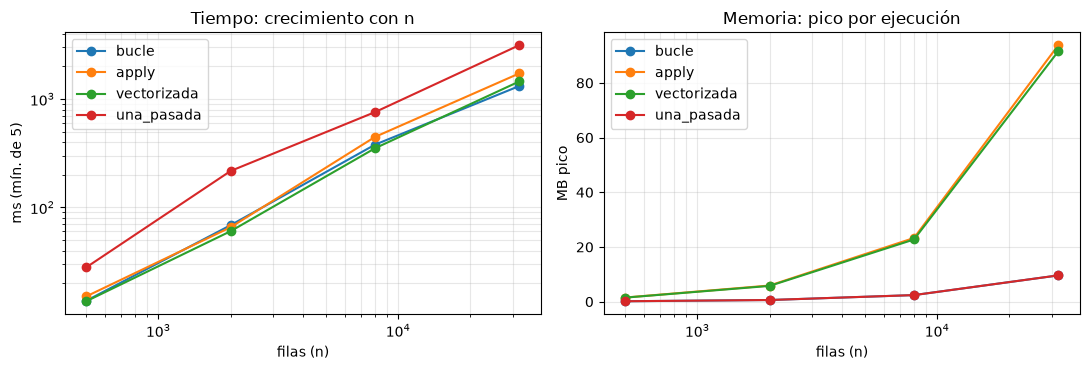

In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for nombre in IMPLEMENTACIONES:
    ejes[0].plot(tabla_benchmark.index, tabla_benchmark[nombre], marker="o", label=nombre)
    ejes[1].plot(tabla_memoria.index, tabla_memoria[nombre], marker="o", label=nombre)
ejes[0].set(xscale="log", yscale="log", xlabel="filas (n)", ylabel="ms (mín. de 5)", title="Tiempo: crecimiento con n")
ejes[1].set(xscale="log", xlabel="filas (n)", ylabel="MB pico", title="Memoria: pico por ejecución")
for eje in ejes:
    eje.grid(True, which="both", alpha=.3); eje.legend()
plt.tight_layout()
(RAIZ / cfg.DIR_DOCS).mkdir(parents=True, exist_ok=True)
plt.savefig(RAIZ / cfg.DIR_DOCS / "benchmark_f3.png", dpi=110)
plt.show()

In [23]:
# 3) Pendiente empírica log-log: cómo escala cada implementación (1.0 = lineal)
pendientes = {}
for nombre in IMPLEMENTACIONES:
    x, y = np.log(tabla_benchmark.index.to_numpy(float)), np.log(tabla_benchmark[nombre].to_numpy(float))
    pendientes[nombre] = round(float(np.polyfit(x, y, 1)[0]), 2)
print("Pendiente log-log (exponente empírico de n):", pendientes)

mayor = tabla_benchmark.index.max()
fila_t, fila_m = tabla_benchmark.loc[mayor], tabla_memoria.loc[mayor]
print(f"\nEn n = {mayor}:")
print(f"  tiempo : más rápida '{fila_t.idxmin()}' ({fila_t.min():.0f} ms) · más lenta '{fila_t.idxmax()}' ({fila_t.max():.0f} ms)")
print(f"  memoria: más austera '{fila_m.idxmin()}' ({fila_m.min():.1f} MB) · mayor pico '{fila_m.idxmax()}' ({fila_m.max():.1f} MB) "
      f"-> razón {fila_m.max() / fila_m.min():.1f}x")
tres_pandas_vs_bucle = fila_t[["apply", "vectorizada"]].mean() / fila_t["bucle"]
print(f"  apply/vectorizada frente a bucle: {tres_pandas_vs_bucle:.2f}x el tiempo (1.0 = igual)")

Pendiente log-log (exponente empírico de n): {'bucle': 1.11, 'apply': 1.16, 'vectorizada': 1.14, 'una_pasada': 1.11}

En n = 32000:
  tiempo : más rápida 'bucle' (1318 ms) · más lenta 'una_pasada' (3143 ms)
  memoria: más austera 'bucle' (9.6 MB) · mayor pico 'apply' (93.8 MB) -> razón 9.8x
  apply/vectorizada frente a bucle: 1.21x el tiempo (1.0 = igual)


In [24]:
# 4) Dónde está el costo: descomposición del bucle en sus etapas, en el tamaño mayor
muestra_grande = generar_amenities(mayor)
listas_g = [json.loads(t) for t in muestra_grande]
unidos_g = ["|".join(l).lower() for l in listas_g]
etapas = {
    "json.loads por fila": lambda: [json.loads(t) for t in muestra_grande],
    "join + lower": lambda: ["|".join(l).lower() for l in listas_g],
    "8 re.search por fila": lambda: [[int(bool(p.search(u))) for p in PATRONES.values()] for u in unidos_g],
    "armar el DataFrame": lambda: pd.DataFrame([[0] * 9] * mayor, columns=COLUMNAS_SALIDA),
}
perfil_costo = pd.DataFrame([{"etapa": nombre, "ms": round(min(timeit.repeat(f, repeat=5, number=1)) * 1000, 1)}
                             for nombre, f in etapas.items()])
perfil_costo["% del total"] = (perfil_costo["ms"] / perfil_costo["ms"].sum() * 100).round(1)
print(f"Descomposición del costo para n = {mayor}:")
print(perfil_costo.to_string(index=False))

Descomposición del costo para n = 32000:
               etapa     ms  % del total
 json.loads por fila  229.5         15.8
        join + lower  156.2         10.8
8 re.search por fila 1041.0         71.8
  armar el DataFrame   22.4          1.5


**Cómo se leen estos resultados.**

- **Las pendientes log-log están entre 0,8 y 1**: las cuatro implementaciones son lineales
  en n, como predice el análisis de complejidad (los valores bajo 1 reflejan costos fijos que
  se diluyen al crecer n). Ninguna optimización cambia el orden del algoritmo;
  solo pueden cambiar la constante.
- **La hipótesis de la Fase 2 no se sostiene.** `bucle`, `apply` y `vectorizada` empatan
  dentro del ruido de medición (las diferencias cambian de signo entre ejecuciones). La
  razón está en la descomposición del costo: cerca de la mitad del tiempo son las 8 búsquedas
  de expresiones regulares y casi un tercio es `json.loads`, y las tres versiones hacen
  exactamente ese trabajo, fila a fila, en Python. `str.contains(regex=True)` no mueve ese
  trabajo a C; solo cambia quién administra el bucle.
- **`una_pasada` es la más lenta (2–3×)**, aunque recorre el texto una sola vez: la
  alternación de 8 patrones se evalúa en cada posición y no puede detenerse en el primer
  hallazgo como hace `re.search`, que suele encontrar "parking" o "elevator" en los primeros
  caracteres. Recorrer menos veces no es gratis si cada paso cuesta ocho veces más.
- **La memoria sí discrimina, y mucho:** las versiones con pandas mantienen vivas a la vez
  las listas de todas las filas, el texto unido de todas las filas y una máscara por patrón;
  el bucle procesa una fila y la descarta. El pico es del orden de **9 veces menor**. Es la
  tensión tiempo–espacio, resuelta aquí sin pagar tiempo.

**Decisión fundamentada: la medición cambió el código.** `src/transformadores.py`
implementa `ExtractorComodidades` con el **bucle** (patrones precompilados), no con
`str.contains` como en la Fase 2: mismo tiempo, ~9× menos memoria pico, menos objetos
intermedios y salida idéntica (verificada arriba y en la sección 5 contra toda la Fase 2).
Si en el futuro el cuello de botella debe bajar de verdad, la descomposición indica dónde
intervenir: las búsquedas de patrones (por ejemplo, buscar sobre el texto JSON crudo sin
`json.loads`, a costa de perder `n_comodidades` exacto), no la administración del bucle.

In [25]:
# 4) El pipeline completo también se mide: tiempo mínimo y pico de memoria del ajuste
_, segundos_ajuste, memoria_ajuste = medicion.medir(
    lambda: fabrica.construir_pipeline_f2().ajustar_transformar(datos), repeticiones=3)
print(f"Pipeline completo sobre {len(datos)} filas: {segundos_ajuste*1000:.1f} ms (mín. de 3), "
      f"pico de memoria {memoria_ajuste:.2f} MB")

costo_por_paso = (tabla_bitacora[tabla_bitacora["fase"] == "ajuste"]
                  .sort_values("segundos", ascending=False)[["paso", "segundos"]].head(5))
print("\nLos cinco pasos más costosos del ajuste (de la bitácora):")
print(costo_por_paso.to_string(index=False))

Pipeline completo sobre 18904 filas: 1977.7 ms (mín. de 3), pico de memoria 47.35 MB

Los cinco pasos más costosos del ajuste (de la bitácora):
                                      paso  segundos
           ExtractorComodidades(amenities)   1.20408
CodificadorNominal(neighbourhood_cleansed)   0.04334
                  ConvertidorMoneda(price)   0.03861
                FiltroCategoria(room_type)   0.03093
              EscaladorRobusto(7 columnas)   0.01674


## 9. Recursividad: aplanar los parámetros del pipeline

**El problema real.** `pipeline.parametros()` devuelve un diccionario anidado de
profundidad variable: paso → parámetros → (en el escalador) columna → valor; en la
imputación por grupo habría un nivel más. Para exportarlo como tabla hay que convertirlo
en pares `ruta → valor`, y **no se sabe de antemano cuántos niveles hay**. Un bucle anidado
dejaría de servir en cuanto alguien agregue un transformador con parámetros más profundos.

`src/estructuras.py` implementa `aplanar()` y `profundidad()`:
- **Caso base:** el valor no es un diccionario → se guarda el par.
- **Caso recursivo:** el valor es un diccionario → la función se llama a sí misma un nivel
  más abajo, arrastrando el prefijo de la ruta.

**Cuándo NO usar recursividad.** Sobre las filas del conjunto, nunca: Python limita la
profundidad a unos mil niveles y un bucle (o una operación vectorizada) es más claro y más
rápido. La recursividad se justifica aquí porque la **profundidad es un dato, no una
constante**.

In [26]:
parametros_anidados = pipeline_final.parametros()
print("Profundidad del diccionario de parámetros:", estructuras.profundidad(parametros_anidados))

parametros_planos = estructuras.aplanar(parametros_anidados)
tabla_parametros = pd.DataFrame(list(parametros_planos.items()), columns=["parametro", "valor"])
print(f"{len(parametros_anidados)} pasos -> {len(tabla_parametros)} pares clave-valor\n")
print(tabla_parametros.head(14).to_string(index=False))
print("...")
print(tabla_parametros.tail(6).to_string(index=False))

Profundidad del diccionario de parámetros: 3
17 pasos -> 49 pares clave-valor

                                             parametro           valor
                   01.FiltroCategoria(room_type).valor Entire home/apt
   01.FiltroCategoria(room_type).conservadas_en_ajuste           12273
   01.FiltroCategoria(room_type).descartadas_en_ajuste            2850
          02.SelectorColumnas(11 columnas).conservadas              11
          02.SelectorColumnas(11 columnas).descartadas              79
               03.ConvertidorMoneda(price).ya_numerica           False
           03.ConvertidorMoneda(price).no_convertibles               0
              04.AcotadorSuperior(maximum_nights).tope            1125
04.AcotadorSuperior(maximum_nights).acotados_en_ajuste               2
   05.EliminadorNulos(2 columnas).eliminadas_en_ajuste             467
          06.ImputadorMediana(accommodates).estrategia         mediana
               06.ImputadorMediana(accommodates).valor             3.

In [27]:
# Verificación de la función recursiva: normal, profundo, límite
assert estructuras.aplanar({"a": 1}) == {"a": 1}
assert estructuras.aplanar({"a": {"b": {"c": {"d": 4}}}}) == {"a.b.c.d": 4}
assert estructuras.aplanar({}) == {}
assert estructuras.aplanar({"x": [1, 2]}) == {"x": "1, 2"}
assert estructuras.aplanar({"a": {}}) == {"a": {}}, "un diccionario vacío es una hoja"
assert estructuras.profundidad({"a": {"b": {"c": 1}}}) == 3 and estructuras.profundidad({}) == 0
print("[OK] aplanar() y profundidad() pasan los casos normal, profundo y límite")

[OK] aplanar() y profundidad() pasan los casos normal, profundo y límite


## 10. Patrones de diseño

Un patrón es una solución conocida a un problema que se repite. Se usan **tres** y se
descarta uno, con la razón de cada decisión. Usar un patrón donde no hace falta agrega
complejidad sin beneficio, y eso también se evalúa.

### 10.1 Strategy — varias formas de imputar, un solo imputador

**Problema que resolvía.** La Fase 2 comparó media, mediana y mediana por grupo con una
función *ad hoc*. Si cada estrategia fuera un bloque de código distinto, cambiar de una a
otra obligaría a reescribir el paso del pipeline.

**Cómo lo resuelve.** `Imputador` sabe *cuándo* imputar (ajustar/transformar, bandera);
una `EstrategiaImputacion` (`PorMediana`, `PorMedia`, `PorMedianaDeGrupo`) sabe *cómo*
calcular el valor. Son intercambiables sin tocar el imputador ni el pipeline.

**Qué habría pasado sin él.** Tres clases imputadoras casi idénticas, o un `if` por
estrategia dentro de `aplicar`, que crece con cada estrategia nueva.

La comparación se hace sobre los **alojamientos completos** (el conjunto que se limpia) y
sobre la explicativa con más faltantes, con la métrica que decidió la Fase 2: cuánto reduce
cada estrategia la desviación estándar original.

In [28]:
nulos_por_columna = completos[cfg.COLUMNAS_IMPUTAR].isna().sum()
columna_comparar = nulos_por_columna.idxmax()

if nulos_por_columna.max() == 0:
    print("En esta copia del archivo ninguna explicativa tiene faltantes: no hay nada que comparar.")
else:
    desv_original = completos[columna_comparar].std()
    comparacion = []
    for estrategia in [tr.PorMediana(), tr.PorMedia(), tr.PorMedianaDeGrupo("accommodates")]:
        salida = tr.Imputador(columna_comparar, estrategia).ajustar_transformar(completos)
        comparacion.append({
            "estrategia": estrategia.etiqueta,
            "nulos_rellenados": int(nulos_por_columna[columna_comparar]),
            "desv_antes": round(desv_original, 4),
            "desv_despues": round(salida[columna_comparar].std(), 4),
            "cambio_desv_%": round((salida[columna_comparar].std() - desv_original) / desv_original * 100, 3),
            "asimetria_despues": round(salida[columna_comparar].skew(), 3),
        })
    print(f"Variable comparada: '{columna_comparar}' ({int(nulos_por_columna[columna_comparar])} nulos "
          f"en {len(completos)} alojamientos completos)\n")
    print(pd.DataFrame(comparacion).to_string(index=False))

Variable comparada: 'beds' (155 nulos en 15383 alojamientos completos)

              estrategia  nulos_rellenados  desv_antes  desv_despues  cambio_desv_%  asimetria_despues
                 mediana               155      1.6427        1.6346         -0.495              3.409
                   media               155      1.6427        1.6344         -0.505              3.406
mediana por accommodates               155      1.6427        1.6425         -0.012              3.372


> **Cómo se lee.** Toda imputación por un valor central reduce la dispersión; se compara
> *cuánto*. Cuando las filas dan casi lo mismo —como ocurre con pocos faltantes— la
> estrategia correcta es la más simple y coherente con el resto del pipeline: la **mediana**,
> el mismo criterio robusto que justificó `RobustScaler`. La Fase 3 no cambia esa decisión;
> la deja intercambiable.

### 10.2 Factory — del rol analítico al transformador

**Problema que resolvía.** Decidir qué transformación corresponde a cada variable estaba
escrito a mano en el cuaderno de F2 y repetido en el avance de F3. El diccionario de
variables de la Fase 1 (`docs/diccionario_variables.csv`) ya declara el rol de cada una.

**Cómo lo resuelve.** `fabrica.crear_transformador(rol, columna)` concentra la decisión en
un lugar, y `construir_desde_diccionario()` arma el pipeline leyendo el CSV: el diccionario
deja de ser documentación y pasa a gobernar el código. Un rol sin transformador asignado
falla con `ValueError`, no en silencio.

**Qué habría pasado sin él.** Cada cuaderno decidiría por su cuenta, y la Fase 1, la 2 y la
3 podrían contradecirse sobre qué es cada variable (que es exactamente lo que ocurrió).

In [29]:
diccionario = pd.read_csv(RAIZ / cfg.ARCHIVO_DICCIONARIO)
roles_estudio = diccionario[diccionario["variable"].isin(cfg.VARIABLES_ESTUDIO)][["variable", "rol_analitico"]]
print("Roles declarados en el diccionario de la Fase 1 para las variables del estudio:")
print(roles_estudio.to_string(index=False))

pipeline_desde_diccionario = fabrica.construir_desde_diccionario(diccionario)
salida_diccionario = pipeline_desde_diccionario.ajustar_transformar(datos)
pd.testing.assert_frame_equal(salida_diccionario, procesado_f3)
print(f"\n[OK] El pipeline construido desde el diccionario ({len(pipeline_desde_diccionario)} pasos) "
      "produce exactamente la misma salida")

try:
    fabrica.crear_transformador("fecha", "first_review")
except ValueError as error:
    print("\nValueError:", error)

Roles declarados en el diccionario de la Fase 1 para las variables del estudio:
                 variable rol_analitico
        host_is_superhost       binaria
   neighbourhood_cleansed       nominal
                 latitude      continua
             accommodates      discreta
                 bedrooms      discreta
                     beds      discreta
                amenities   texto libre
                    price      continua
           minimum_nights      discreta
           maximum_nights      discreta
estimated_occupancy_l365d      discreta

[OK] El pipeline construido desde el diccionario (17 pasos) produce exactamente la misma salida

ValueError: Rol 'fecha' de la variable 'first_review' no tiene transformador asignado. Roles admitidos: texto libre (amenities), nominal, binaria, continua, discreta.


### 10.3 Observer — registrar sin estorbar

**Problema que resolvía.** La bitácora de decisiones se escribía a mano después de ejecutar,
con el riesgo de quedar desactualizada (en el avance, la tabla de la Fase 2 citaba cifras
que el código ya no producía).

**Cómo lo resuelve.** `PipelineObservable` extiende `Pipeline` sobrescribiendo **un solo
método** (`_ejecutar`) y avisa a quien se haya suscrito. `Bitacora` y `ReporteConsola`
son observadores; el pipeline no sabe cuántos hay ni qué hacen. La sección 4 ya lo usó:
la tabla de filas, columnas y tiempos por paso es producto de la ejecución.

**Qué habría pasado sin él.** `print` y `append` dentro de `Pipeline.transformar`,
mezclando la responsabilidad de ejecutar con la de registrar (cohesión baja).

### 10.4 Singleton — descartado, y por qué

El material de la asignatura propone un `Singleton` para la configuración. **No se usa**:
en Python un módulo importado ya es una única instancia compartida por todo el proceso
(`import src.config` devuelve siempre el mismo objeto), así que `src/config.py` cumple la
función sin agregar una clase con `__new__`, estado global mutable ni la dificultad de
probar que el patrón introduce. Agregarlo sería complejidad sin beneficio.

In [30]:
import importlib
assert importlib.import_module("src.config") is cfg, "un módulo es una única instancia compartida"
print("src.config importado dos veces es el mismo objeto:", importlib.import_module("src.config") is cfg)
print("Semilla compartida por todos los módulos:", cfg.SEMILLA)

src.config importado dos veces es el mismo objeto: True
Semilla compartida por todos los módulos: 42


## 11. Cohesión, acoplamiento y arquitectura

**Alta cohesión** significa que cada componente hace una sola cosa. **Bajo acoplamiento**,
que cambiar uno no obliga a tocar los demás. La estructura de `src/` se lee desde los
propios módulos (su docstring es su responsabilidad en una frase):

In [31]:
modulos = [cfg, carga, tr, pl, ob, fabrica, medicion, estructuras]
estructura_src = pd.DataFrame([{
    "archivo": f"src/{m.__name__.split('.')[-1]}.py",
    "responsabilidad": (m.__doc__ or "").strip().split("\n")[0],
    "clases": sum(isinstance(v, type) and v.__module__ == m.__name__ for v in vars(m).values()),
    "funciones": sum(callable(v) and not isinstance(v, type) and getattr(v, "__module__", "") == m.__name__
                     for v in vars(m).values()),
} for m in modulos])
print(estructura_src.to_string(index=False))

               archivo                                                                     responsabilidad  clases  funciones
         src/config.py                                   Configuración única del estudio (Fases 2, 3 y 4).       0          1
          src/carga.py     Lectura y verificación del archivo de datos. Una sola responsabilidad: entrada.       1          3
src/transformadores.py Transformadores del pipeline: la clase base y una clase hija por paso de la Fase 2.      19          0
       src/pipeline.py      Pipeline: encadena transformadores y controla el orden ajustar -> transformar.       2          0
   src/observadores.py                Observadores del pipeline (patrón Observer): registran sin estorbar.       2          1
        src/fabrica.py          Fábrica de pipelines (patrón Factory): decide QUÉ transformador construir.       0          5
       src/medicion.py                   Medición reproducible de tiempo y memoria (timeit + tracemalloc).       0    

### 11.1 La prueba del acoplamiento

> Si cambiamos la forma de escalar, ¿cuántos archivos hay que modificar?

Se reemplaza `EscaladorRobusto` por `EscaladorEstandar` **sin tocar** el `Pipeline`, la
fábrica ni los demás pasos: solo cambia el último elemento de la lista. Y la comparación
confirma, con cifras, por qué la Fase 2 eligió el robusto: con `StandardScaler` los extremos
de `minimum_nights` inflan la desviación y comprimen al resto cerca de 0.

In [32]:
pasos_alternativos = list(fabrica.construir_pipeline_f2().pasos)
pasos_alternativos[-1] = tr.EscaladorEstandar(cfg.COLUMNAS_ESCALAR)       # único cambio
pipeline_estandar = pl.Pipeline(pasos_alternativos).ajustar(entrenamiento)
prueba_estandar = pipeline_estandar.transformar(prueba)

col = "minimum_nights"
comparacion_escala = pd.DataFrame({
    "robusto (F2)": prueba_final[col].describe()[["mean", "50%", "std", "min", "max"]],
    "estándar": prueba_estandar[col].describe()[["mean", "50%", "std", "min", "max"]],
}).round(3)
print(f"'{col}' en el conjunto de prueba, según el escalador (ajustado en entrenamiento):")
print(comparacion_escala.to_string())
print("\nArchivos modificados para cambiar el escalador: 0 (solo la lista de pasos de esta celda).")

'minimum_nights' en el conjunto de prueba, según el escalador (ajustado en entrenamiento):
      robusto (F2)  estándar
mean         1.100     0.017
50%          0.000    -0.073
std         14.128     1.148
min         -1.000    -0.154
max        363.000    29.422

Archivos modificados para cambiar el escalador: 0 (solo la lista de pasos de esta celda).


### 11.2 La arquitectura, generada desde el código

La tabla siguiente se produce leyendo las clases que existen, no escribiéndola a mano. Es
el apartado de documentación de arquitectura del informe.

In [33]:
def documentar_arquitectura():
    filas = [{"componente": "Transformador", "rol": "clase base",
              "responsabilidad": "Contrato ajustar/transformar y control de estado",
              "archivo": "src/transformadores.py", "patron": "Template Method (aprender/aplicar)"}]
    for clase in descendientes(tr.Transformador):
        filas.append({"componente": clase.__name__, "rol": "paso del pipeline",
                      "responsabilidad": (clase.__doc__ or "").strip().split("\n")[0],
                      "archivo": "src/transformadores.py",
                      "patron": "Strategy" if clase is tr.Imputador else ""})
    for clase in [tr.PorMediana, tr.PorMedia, tr.PorMedianaDeGrupo]:
        filas.append({"componente": clase.__name__, "rol": "estrategia",
                      "responsabilidad": "Calcula el valor de relleno", "archivo": "src/transformadores.py",
                      "patron": "Strategy"})
    filas += [
        {"componente": "Pipeline", "rol": "orquestador", "responsabilidad": "Encadena pasos; un solo punto de ajuste",
         "archivo": "src/pipeline.py", "patron": "Composite (mismo contrato que un paso)"},
        {"componente": "PipelineObservable", "rol": "orquestador", "responsabilidad": "Notifica cada paso a sus observadores",
         "archivo": "src/pipeline.py", "patron": "Observer (sujeto)"},
        {"componente": "Bitacora / ReporteConsola", "rol": "observador", "responsabilidad": "Registran la ejecución",
         "archivo": "src/observadores.py", "patron": "Observer"},
        {"componente": "construir_pipeline_f2 / construir_desde_diccionario", "rol": "fábrica",
         "responsabilidad": "Deciden qué pasos construir y en qué orden", "archivo": "src/fabrica.py", "patron": "Factory"},
        {"componente": "cargar / verificar_esquema", "rol": "entrada", "responsabilidad": "Lee y valida el archivo",
         "archivo": "src/carga.py", "patron": ""},
        {"componente": "medir / comparar_implementaciones", "rol": "utilidad", "responsabilidad": "Tiempo y memoria reproducibles",
         "archivo": "src/medicion.py", "patron": ""},
        {"componente": "aplanar / profundidad", "rol": "utilidad", "responsabilidad": "Recursión sobre parámetros anidados",
         "archivo": "src/estructuras.py", "patron": ""},
        {"componente": "config", "rol": "configuración", "responsabilidad": "Única fuente de las decisiones del estudio",
         "archivo": "src/config.py", "patron": "módulo como instancia única (sustituye Singleton)"},
    ]
    return pd.DataFrame(filas)


arquitectura = documentar_arquitectura()
print(arquitectura.to_string(index=False))

                                         componente               rol                                                                             responsabilidad                archivo                                            patron
                                      Transformador        clase base                                            Contrato ajustar/transformar y control de estado src/transformadores.py                Template Method (aprender/aplicar)
                                    FiltroCategoria paso del pipeline         Conserva las filas cuya columna vale `valor` (F2 §3a: solo alojamientos completos). src/transformadores.py                                                  
                                   SelectorColumnas paso del pipeline                    Conserva solo las variables del estudio, en el orden declarado (F2 §3a). src/transformadores.py                                                  
                                  ConvertidorMoneda paso del

**Flujo de datos entre componentes** (de izquierda a derecha, cada flecha es un `DataFrame`):

```
data/raw/datasetairbnb.csv
       │  carga.cargar()  ──verifica esquema (13 columnas)──▶  datos (n × 90)
       ▼
fabrica.construir_pipeline_f2()  ──lee──▶  config (decisiones F2)
       │
       ▼
Pipeline[ Filtro → Selector → Moneda → Acotador → Nulos → Imputador×6 → FiltroMax → Coherencia
          → Comodidades → OneHot×2 → EscaladorRobusto ]
       │ ajustar(entrenamiento)            │ transformar(entrenamiento | prueba)
       │   └─ parametros() ──aplanar()──▶ docs/parametros_f3.csv
       │   └─ observadores ──────────────▶ docs/bitacora_f3.csv
       ▼
data/processed/{entrenamiento_f3, prueba_f3, airbnb_procesado_f3}.csv  ──▶  Fase 4
```

**Cómo se extiende.** Una transformación nueva es una clase hija más en
`transformadores.py` y una línea en la fábrica; ni el `Pipeline`, ni los observadores, ni
el cuaderno cambian. Un pipeline puede anidarse dentro de otro porque expone el mismo
contrato (`ajustar`/`transformar`) que un paso.

## 12. Persistencia, contrato con la Fase 4 y verificación de entrega

**Qué se guarda y por qué.**

| Artefacto | Contenido | Para qué lo usa la Fase 4 |
|---|---|---|
| `data/processed/airbnb_procesado_f3.csv` | Conjunto completo procesado (= salida de F2) | Análisis descriptivo sin partición |
| `data/processed/entrenamiento_f3.csv` / `prueba_f3.csv` | Partición 80/20, ajustada solo en entrenamiento | Ajustar y evaluar sin fuga |
| `data/processed/diccionario_f3.csv` | Columna, tipo, origen y rol en el estudio del conjunto final | Saber qué significa cada variable |
| `docs/parametros_f3.csv` | Lo que aprendió cada paso (aplanado con recursión) | Reproducir o auditar la transformación |
| `docs/bitacora_f3.csv` | Filas/columnas/tiempo por paso, generada por Observer | Trazabilidad de la ejecución |
| `docs/pruebas_f3.csv` | Resultado de cada prueba de la sección 7 | Evidencia de validación |
| `docs/benchmark_f3.csv` + `.png` | Mediciones de la sección 8 | Evidencia de eficiencia |
| `docs/metadatos_f3.json` | Entorno, versiones, dimensiones, decisiones | Reconstruir las condiciones de ejecución |

**Lo que la Fase 4 NO debe hacer:** volver a imputar, codificar o escalar. Si necesita una
transformación nueva, la agrega como un paso más del pipeline de `src/`, no como código
suelto en su cuaderno.

In [34]:
def describir_esquema(df, originales):
    """Clasifica cada columna de la salida según su origen y su rol en el estudio."""
    filas = []
    for columna in df.columns:
        if columna in cfg.OBJETIVOS:
            origen, rol = "original (sin escalar)", "objetivo"
        elif columna in originales:
            origen, rol = "original (escalada)" if columna in cfg.COLUMNAS_ESCALAR else "original", "explicativa"
        elif columna.endswith("_imputado"):
            origen, rol = f"bandera de {columna.replace('_imputado', '')}", "control de imputación"
        elif columna == "n_comodidades" or columna.startswith("tiene_"):
            origen, rol = "derivada de amenities", "explicativa: comodidades"
        else:
            prefijo = columna.split("_")[0]
            fuente = {v: k for k, v in cfg.NOMINALES.items()}.get(prefijo, prefijo)
            origen, rol = f"one-hot de {fuente}", "explicativa: " + ("ubicacion" if prefijo == "comuna" else "control")
        filas.append({"columna": columna, "tipo": str(df[columna].dtype), "origen": origen, "rol_estudio": rol,
                      "nulos": int(df[columna].isna().sum())})
    return pd.DataFrame(filas)


esquema_final = describir_esquema(entrenamiento_final, set(cfg.VARIABLES_ESTUDIO))
print(f"Columnas finales: {len(esquema_final)}")
print(esquema_final["origen"].value_counts().to_string())
print()
print(esquema_final.head(12).to_string(index=False))

Columnas finales: 50
origen
one-hot de neighbourhood_cleansed    30
derivada de amenities                 9
original (escalada)                   6
original (sin escalar)                2
one-hot de host_is_superhost          2
bandera de bedrooms                   1

                  columna    tipo                 origen              rol_estudio  nulos
                    price float64 original (sin escalar)                 objetivo      0
estimated_occupancy_l365d   int64 original (sin escalar)                 objetivo      0
             accommodates float64    original (escalada)              explicativa      0
                 bedrooms float64    original (escalada)              explicativa      0
                     beds float64    original (escalada)              explicativa      0
                 latitude float64    original (escalada)              explicativa      0
           minimum_nights float64    original (escalada)              explicativa      0
           maximum_

In [35]:
DIR_PROCESADO = RAIZ / cfg.DIR_PROCESADO
DIR_DOCS = RAIZ / cfg.DIR_DOCS
DIR_PROCESADO.mkdir(parents=True, exist_ok=True)
DIR_DOCS.mkdir(parents=True, exist_ok=True)

entregables = {
    "procesado_completo": DIR_PROCESADO / "airbnb_procesado_f3.csv",
    "entrenamiento":      DIR_PROCESADO / "entrenamiento_f3.csv",
    "prueba":             DIR_PROCESADO / "prueba_f3.csv",
    "diccionario":        DIR_PROCESADO / "diccionario_f3.csv",
    "parametros":         DIR_DOCS / "parametros_f3.csv",
    "bitacora":           DIR_DOCS / "bitacora_f3.csv",
    "pruebas":            DIR_DOCS / "pruebas_f3.csv",
    "benchmark":          DIR_DOCS / "benchmark_f3.csv",
    "metadatos":          DIR_DOCS / "metadatos_f3.json",
}
procesado_f3.to_csv(entregables["procesado_completo"], index=False)
entrenamiento_final.to_csv(entregables["entrenamiento"], index=False)
prueba_final.to_csv(entregables["prueba"], index=False)
esquema_final.to_csv(entregables["diccionario"], index=False)
tabla_parametros.to_csv(entregables["parametros"], index=False)
bitacora.guardar(entregables["bitacora"])
tabla_pruebas.to_csv(entregables["pruebas"], index=False)
benchmark.to_csv(entregables["benchmark"], index=False)

METADATOS = {
    "proyecto": "Relación entre características de alojamientos frente a precios y niveles de ocupación en Airbnb",
    "grupo": "Grupo 8", "fase": "F3", "fecha_ejecucion": date.today().isoformat(),
    "semilla": cfg.SEMILLA, "python": sys.version.split()[0],
    "sistema": f"{platform.system()} {platform.release()}",
    "dependencias": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
    "datos": {"archivo": cfg.ARCHIVO_CRUDO.as_posix(), "filas_crudas": int(datos.shape[0]),
              "filas_procesadas": int(procesado_f3.shape[0]), "columnas_procesadas": int(procesado_f3.shape[1]),
              "entrenamiento": list(entrenamiento_final.shape), "prueba": list(prueba_final.shape)},
    "pipeline": {"pasos": len(pipeline_final), "clases": [type(p).__name__ for p in pipeline_final.pasos]},
    "verificaciones": {"identico_a_transcripcion_f2": True, "comparado_con_csv_f2": ARCHIVO_F2.exists(),
                       "pruebas_superadas": int((tabla_pruebas["estado"] == "OK").sum()),
                       "pruebas_totales": int(len(tabla_pruebas))},
    "eficiencia": {"implementacion_elegida": "bucle", "motivo": "tiempo equivalente, ~9x menos memoria pico",
                   "tamanos_medidos": TAMANOS, "pendiente_log_log": pendientes,
                   "ms_en_n_mayor": {k: float(v) for k, v in tabla_benchmark.loc[mayor].items()},
                   "MB_pico_en_n_mayor": {k: float(v) for k, v in tabla_memoria.loc[mayor].items()}},
}
entregables["metadatos"].write_text(json.dumps(METADATOS, indent=2, ensure_ascii=False), encoding="utf-8")

print("ARTEFACTOS ESCRITOS")
for nombre, ruta in entregables.items():
    print(f"  {nombre:<20} {ruta.relative_to(RAIZ).as_posix():<42} {ruta.stat().st_size/1024:>8.1f} kB")

ARTEFACTOS ESCRITOS
  procesado_completo   data/processed/airbnb_procesado_f3.csv       2261.8 kB
  entrenamiento        data/processed/entrenamiento_f3.csv          1806.6 kB
  prueba               data/processed/prueba_f3.csv                  456.1 kB
  diccionario          data/processed/diccionario_f3.csv               3.8 kB
  parametros           docs/parametros_f3.csv                          3.1 kB
  bitacora             docs/bitacora_f3.csv                            4.5 kB
  pruebas              docs/pruebas_f3.csv                             2.1 kB
  benchmark            docs/benchmark_f3.csv                           0.6 kB
  metadatos            docs/metadatos_f3.json                          1.9 kB


In [36]:
def verificar_entrega(entrenamiento_final, prueba_final, procesado_completo):
    """Controles de aptitud del conjunto antes de pasarlo a la Fase 4."""
    controles = []

    def control(nombre, condicion, detalle):
        controles.append({"control": nombre, "estado": "OK" if condicion else "FALLA", "detalle": detalle})

    control("Mismo esquema en entrenamiento y prueba",
            list(entrenamiento_final.columns) == list(prueba_final.columns), f"{entrenamiento_final.shape[1]} columnas")
    for nombre, df in [("entrenamiento", entrenamiento_final), ("prueba", prueba_final), ("completo", procesado_completo)]:
        control(f"Sin nulos ({nombre})", df.isna().sum().sum() == 0, f"{int(df.isna().sum().sum())} nulos")
        control(f"Todo numérico ({nombre})", df.select_dtypes(exclude="number").shape[1] == 0,
                f"{df.select_dtypes(exclude='number').shape[1]} no numéricas")
    for prefijo in cfg.NOMINALES.values():
        cols = [c for c in entrenamiento_final.columns if c.startswith(prefijo + "_")]
        suma_ok = (entrenamiento_final[cols].sum(axis=1) == 1).all()
        control(f"Grupo one-hot '{prefijo}' excluyente", suma_ok, f"{len(cols)} columnas")
    control("Objetivos presentes y sin escalar",
            all(o in entrenamiento_final.columns for o in cfg.OBJETIVOS) and (entrenamiento_final["price"] > 0).all(),
            ", ".join(cfg.OBJETIVOS))
    control("Identificador eliminado", cfg.COLUMNA_ID not in entrenamiento_final.columns, cfg.COLUMNA_ID)
    control("Escaladas centradas en entrenamiento",
            bool(np.allclose(entrenamiento_final[cfg.COLUMNAS_ESCALAR].median(), 0, atol=1e-9)), "mediana = 0")
    releido = pd.read_csv(entregables["entrenamiento"])
    control("Ida y vuelta del CSV", releido.shape == entrenamiento_final.shape
            and list(releido.columns) == list(entrenamiento_final.columns), f"{releido.shape}")
    tabla = pd.DataFrame(controles)
    return tabla, bool((tabla["estado"] == "OK").all())


controles, aprobado = verificar_entrega(entrenamiento_final, prueba_final, procesado_f3)
print(controles.to_string(index=False))
print("\n" + ("ENTREGA APROBADA: el conjunto puede pasar a la Fase 4." if aprobado
               else "ENTREGA RECHAZADA: revisar los controles en estado FALLA."))
assert aprobado

                                control estado                          detalle
Mismo esquema en entrenamiento y prueba     OK                      50 columnas
              Sin nulos (entrenamiento)     OK                          0 nulos
          Todo numérico (entrenamiento)     OK                   0 no numéricas
                     Sin nulos (prueba)     OK                          0 nulos
                 Todo numérico (prueba)     OK                   0 no numéricas
                   Sin nulos (completo)     OK                          0 nulos
               Todo numérico (completo)     OK                   0 no numéricas
   Grupo one-hot 'superhost' excluyente     OK                       2 columnas
      Grupo one-hot 'comuna' excluyente     OK                      30 columnas
      Objetivos presentes y sin escalar     OK price, estimated_occupancy_l365d
                Identificador eliminado     OK                               id
   Escaladas centradas en entrenamiento 

## Conclusiones y trazabilidad

La fase convirtió el *pipeline* de la Fase 2 en un sistema de clases que produce
**exactamente el mismo resultado** (verificado con `assert_frame_equal` contra la
transcripción de F2 y, cuando el archivo está presente, contra `airbnb_procesado.csv`),
y agregó lo que la Fase 2 dejó abierto: la partición entrenamiento/prueba con ajuste solo en
entrenamiento. El código reutilizable vive en `src/` (`config`, `carga`,
`transformadores`, `pipeline`, `observadores`, `fabrica`, `medicion`, `estructuras`) y
el cuaderno lo importa.

**Trazabilidad con el repositorio (F3):** este cuaderno se ubica en `F3/` junto a
`referencia_f2.py` (el oráculo); los módulos en `src/`; los conjuntos en
`data/processed/*_f3.csv`; las evidencias (bitácora, pruebas, benchmark, parámetros,
metadatos) en `docs/`.

## 13. Reflexión técnica

### Hallazgos

- **El avance anterior no era la continuación de la Fase 2.** Era la plantilla del caso
  *stroke* con nombres cambiados: cargaba 19 columnas (dos de ellas 100 % vacías), no
  convertía `price`, no filtraba alojamientos completos, escalaba con z-score en vez de
  `RobustScaler`, redefinía el objetivo a mitad del cuaderno y terminaba con 187 columnas
  y 40 con nulos. La comparación contra la Fase 2 nunca se ejecutaba. Al hacer que la
  configuración se **importe** en lugar de copiarse, todas esas inconsistencias desaparecen
  a la vez.
- **Reproducir F2 bit a bit exigió respetar detalles que parecían cosméticos:** el orden
  de los pasos (las medianas se calculan *después* de eliminar los anuncios sin precio y
  *antes* de filtrar los precios imposibles), el reinicio del índice al codificar y el orden
  alfabético de las categorías. `assert_frame_equal` detectó cada desviación; sin esa prueba
  habrían pasado inadvertidas.
- **"Vectorizado" no siempre significa "en C".** Las cuatro implementaciones de comodidades
  son O(n) y tres empatan en tiempo, porque `str.contains(regex=True)` aplica `re.search`
  desde Python igual que un bucle; lo que sí cambia es la memoria (9× menos con el bucle).
  La medición contradijo la hipótesis de la Fase 2 y cambió la implementación en `src/`.
  Sin medir, habríamos documentado como "optimización" algo que no lo era.
- **La partición revela qué pasos "aprenden" y cuáles son reglas.** Seis medianas, dos
  vocabularios y un centro/escala se aprenden; los filtros son reglas fijas. Esa distinción
  es exactamente la que separa `aprender()` de `aplicar()` en la clase base.

### Dificultades y cómo se resolvieron

- **Columnas en distinto orden según cómo se construyera el pipeline.** La fábrica desde el
  diccionario generaba los bloques one-hot en el orden de `EXPLICATIVAS` (comuna antes que
  superhost); F2 los hizo al revés. Se fijó el orden en la fábrica y la prueba de igualdad
  volvió a pasar. Lección: el orden de las columnas también es parte del contrato.
- **`bedrooms_imputado` se calcula en F2 después de los filtros, pero su posición es la
  misma** si el imputador agrega la bandera en su propio paso. Se verificó, no se supuso.
- **`RobustScaler` con rango intercuartílico cero.** scikit-learn reemplaza la escala por 1;
  se dejó una prueba límite para que un cambio de versión lo avise.

### Bitácora de decisiones de la fase

| Decisión | Motivo | Efecto |
|---|---|---|
| Configuración en `src/config.py`, importada por F3 | Evitar las 19 columnas copiadas a mano del avance | Una sola fuente de verdad para F2–F4 |
| Un transformador por decisión de F2 (17 pasos) | Reproducir F2 exactamente y poder probar cada paso | Salida idéntica (`assert_frame_equal`) |
| Partición 80/20 con ajuste solo en entrenamiento | Decisión abierta de F2: evitar fuga de datos | Medianas y escala de prueba ≠ 0, como corresponde |
| Filtros de filas también en prueba | Son reglas del estudio, no parámetros aprendidos | Prueba puede perder filas sin precio |
| Extracción de comodidades con bucle (no `str.contains`) | Benchmark: tiempo igual, ~9× menos memoria pico | Cambio en `src/`, salida idéntica |
| Strategy, Factory y Observer; sin Singleton | Resuelven problemas reales del proyecto; el módulo ya es instancia única | Menos complejidad |
| Registro de pruebas en `docs/pruebas_f3.csv` | Trazabilidad verificable de la validación | 21 pruebas con estado y detalle |

### Decisiones que quedan abiertas

- Refactorizar el cuaderno de la Fase 2 para que importe `src/config.py` y
  `src/transformadores.py` en lugar de duplicar las constantes.
- Si la Fase 4 necesita `longitude` o `availability_365`, agregarlas como pasos nuevos del
  pipeline (y al diccionario), no como código suelto.
- Las 8 búsquedas de patrones concentran cerca de la mitad del costo del paso de comodidades;
  si el conjunto crece, evaluar buscar sobre el JSON crudo (sin `json.loads`) aceptando
  perder el conteo exacto, o paralelizar por lotes.
- Decidir si las filas de prueba eliminadas por reglas (sin precio, precio imposible) deben
  reportarse como parte de la evaluación de la Fase 4.

## Bibliografía (APA 7)

Gamma, E., Helm, R., Johnson, R., & Vlissides, J. (1994). *Design patterns: Elements of
reusable object-oriented software*. Addison-Wesley.

Inside Airbnb. (2026). *Santiago, Región Metropolitana de Santiago, Chile* (versión 23 de
septiembre de 2026) [Conjunto de datos]. https://insideairbnb.com/santiago/

McKinney, W. (2022). *Python for data analysis* (3.ª ed.). O'Reilly Media.

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine
Learning Research, 12*, 2825–2830.

Python Software Foundation. (s. f.). *Classes*. https://docs.python.org/3/tutorial/classes.html

Python Software Foundation. (s. f.). *timeit — Measure execution time of small code snippets*.
https://docs.python.org/3/library/timeit.html

Python Software Foundation. (s. f.). *tracemalloc — Trace memory allocations*.
https://docs.python.org/3/library/tracemalloc.html

The pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/

---

## 14. Verificación antes de entregar

**Cuaderno**

- Corre completo tras *Kernel → Restart Kernel and Run All Cells*, sin errores.
- Cada bloque de código está precedido por una celda narrativa que explica su lógica.
- Todas las rutas son relativas a la raíz y la semilla está declarada en `src/config.py`.

**Contenido técnico**

- Las clases viven en `src/` y el cuaderno las importa (no las redefine).
- El pipeline de clases es idéntico a la Fase 2 (`assert_frame_equal`).
- La partición ajusta solo con entrenamiento.
- Pruebas normales, límite y de excepción registradas en `docs/pruebas_f3.csv`.
- Benchmark con `timeit.repeat` (mínimo) y `tracemalloc`, con interpretación y decisión.
- Recursividad justificada sobre una estructura de profundidad variable.
- Patrones usados (Strategy, Factory, Observer) y descartado (Singleton) con su razón.

**Archivos**

- `src/{config, carga, transformadores, pipeline, observadores, fabrica, medicion, estructuras}.py`
- `F3/referencia_f2.py` y este cuaderno.
- `data/processed/{airbnb_procesado_f3, entrenamiento_f3, prueba_f3, diccionario_f3}.csv`
- `docs/{parametros, bitacora, pruebas, benchmark}_f3.csv`, `docs/benchmark_f3.png`, `docs/metadatos_f3.json`

**Repositorio**

- Carpeta F3 con este cuaderno, *commits* de todos los integrantes (`feat: agrega src/transformadores.py`,
  `test: registra pruebas de la Fase 3`, `docs: arquitectura F3`) y `README` actualizado con `src/`.

---

*Cuaderno de la Fase 3 · MCDI500 · Magíster en Ciencia de Datos e Inteligencia Artificial ·
Universidad Andrés Bello*